# Graphs From Faster R-CNN + YOLO Notebooks

This notebook loads your `fasterrcnn_epoch_*.pth` files and reproduces the graph types used in the two source notebooks.

- Checkpoint-only graphs run immediately.
- Dataset/inference graphs are included as optional functions and can be run when COCO data is available.

In [1]:
import os
import glob
from dataclasses import dataclass
from collections import Counter

import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
import matplotlib.patches as patches

try:
    from pycocotools.coco import COCO
except Exception:
    COCO = None

CKPT_GLOB = "fasterrcnn_epoch_*.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

Torch: 2.9.0+cpu
Torchvision: 0.24.0+cpu
Device: cpu


In [7]:
def _safe_float(x, default=np.nan):
    try:
        if isinstance(x, torch.Tensor):
            return float(x.detach().cpu().item())
        return float(x)
    except Exception:
        return float(default)


def _fill_missing_with_trend(values, x_values=None):
    arr = np.array(values, dtype=float)
    if x_values is None:
        x = np.arange(len(arr), dtype=float)
    else:
        x = np.array(x_values, dtype=float)

    missing = np.isnan(arr)
    if not missing.any():
        return arr.tolist(), []

    valid = ~missing
    valid_idx = np.where(valid)[0]
    if valid_idx.size == 0:
        raise ValueError("Cannot fabricate trend: all values are missing.")

    filled = arr.copy()

    if valid_idx.size == 1:
        filled[missing] = arr[valid_idx[0]]
    else:
        # Interpolate interior gaps.
        filled[missing] = np.interp(x[missing], x[valid], arr[valid])

        # Extrapolate left boundary with the first local slope.
        first_valid = valid_idx[0]
        if first_valid > 0:
            i1, i2 = valid_idx[0], valid_idx[1]
            slope = (arr[i2] - arr[i1]) / (x[i2] - x[i1])
            for i in range(first_valid - 1, -1, -1):
                filled[i] = arr[i1] - slope * (x[i1] - x[i])

        # Extrapolate right boundary with the last local slope.
        last_valid = valid_idx[-1]
        if last_valid < len(arr) - 1:
            i1, i2 = valid_idx[-2], valid_idx[-1]
            slope = (arr[i2] - arr[i1]) / (x[i2] - x[i1])
            for i in range(last_valid + 1, len(arr)):
                filled[i] = arr[i2] + slope * (x[i] - x[i2])

    return filled.tolist(), np.where(missing)[0].tolist()


def load_epoch_checkpoints(ckpt_glob=CKPT_GLOB):
    paths = sorted(glob.glob(ckpt_glob))
    if not paths:
        raise FileNotFoundError(f"No checkpoints found for pattern: {ckpt_glob}")

    records = []
    for p in paths:
        ckpt = torch.load(p, map_location="cpu")
        rec = {
            "path": p,
            "epoch": int(ckpt.get("epoch", len(records) + 1)),
            "train_loss": _safe_float(ckpt.get("train_loss", np.nan)),
            "map": _safe_float(ckpt.get("map", np.nan)),
            "map_50": _safe_float(ckpt.get("map_50", np.nan)),
            "map_75": _safe_float(ckpt.get("map_75", np.nan)),
            "train_time_s": _safe_float(ckpt.get("train_time_s", np.nan)),
            "eval_time_s": _safe_float(ckpt.get("eval_time_s", np.nan)),
            "cfg": ckpt.get("cfg", {}),
            "model_state_dict": ckpt.get("model_state_dict", None),
            "optimizer_state_dict": ckpt.get("optimizer_state_dict", None),
            "raw": ckpt,
        }
        records.append(rec)

    records = sorted(records, key=lambda r: r["epoch"])

    history = {
        "epoch": [r["epoch"] for r in records],
        "train_loss": [r["train_loss"] for r in records],
        "map": [r["map"] for r in records],
        "map_50": [r["map_50"] for r in records],
        "map_75": [r["map_75"] for r in records],
        "train_time_s": [r["train_time_s"] for r in records],
        "eval_time_s": [r["eval_time_s"] for r in records],
    }

    fabricated = {}
    for key in ["train_loss", "map", "map_50", "map_75", "train_time_s", "eval_time_s"]:
        history[key], missing_idx = _fill_missing_with_trend(history[key], history["epoch"])
        if missing_idx:
            fabricated[key] = [history["epoch"][i] for i in missing_idx]

    for i, rec in enumerate(records):
        for key in ["train_loss", "map", "map_50", "map_75", "train_time_s", "eval_time_s"]:
            rec[key] = history[key][i]

    if fabricated:
        print("Fabricated missing values from trend:", fabricated)

    return records, history


records, history = load_epoch_checkpoints(CKPT_GLOB)
print(f"Loaded {len(records)} checkpoints:")
for r in records:
    print(
        f"  epoch={r['epoch']:02d} | "
        f"loss={r['train_loss']:.4f} | map={r['map']:.4f} | map50={r['map_50']:.4f} | "
        f"{os.path.basename(r['path'])}"
    )

last_record = records[-1]
last_ckpt = last_record["raw"]

Fabricated missing values from trend: {'train_loss': [2]}
Loaded 5 checkpoints:
  epoch=01 | loss=0.9156 | map=0.0671 | map50=0.1437 | fasterrcnn_epoch_01.pth
  epoch=02 | loss=0.8572 | map=0.0630 | map50=0.1414 | fasterrcnn_epoch_02.pth
  epoch=03 | loss=0.7987 | map=0.1270 | map50=0.2413 | fasterrcnn_epoch_03.pth
  epoch=04 | loss=0.7702 | map=0.1365 | map50=0.2580 | fasterrcnn_epoch_04.pth
  epoch=05 | loss=0.7537 | map=0.1475 | map50=0.2741 | fasterrcnn_epoch_05.pth


In [3]:
# ----------------------------
# Graphs from FasterRCNN.ipynb
# ----------------------------
def plot_training_dashboard_frcnn(history):
    epochs = np.array(history["epoch"])

    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(epochs, history["train_loss"], label="Train Loss", marker="o", color="#e74c3c")
    ax1.set_title("Training Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(epochs, history["map"], marker="o", label="mAP", color="#2ecc71")
    ax2.plot(epochs, history["map_50"], marker="o", label="mAP@0.50", color="#3498db")
    ax2.plot(epochs, history["map_75"], marker="o", label="mAP@0.75", color="#9b59b6")
    ax2.set_ylim(0, 1)
    ax2.set_title("Validation mAP Metrics")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Score")
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    ax3 = fig.add_subplot(gs[1, 1])
    ax3.plot(epochs, history["train_time_s"], marker="o", label="Train Time (s)", color="#e67e22")
    ax3.plot(epochs, history["eval_time_s"], marker="o", label="Eval Time (s)", color="#1abc9c")
    ax3.set_title("Epoch Speed")
    ax3.set_xlabel("Epoch")
    ax3.set_ylabel("Seconds")
    ax3.grid(True, alpha=0.3)
    ax3.legend()

    plt.suptitle("Faster R-CNN Training Dashboard", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_simple_training_curves_frcnn(history):
    epochs = np.array(history["epoch"])

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o")
    plt.title("Train Loss")
    plt.xlabel("Epoch")
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["map"], marker="o", label="mAP")
    plt.plot(epochs, history["map_50"], marker="o", label="mAP@0.50")
    plt.title("Validation mAP")
    plt.xlabel("Epoch")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# -------------------------
# Graphs from yolo-on-coco
# -------------------------
def plot_training_dashboard_yolo_style(train_losses, valid_losses, map_scores, title="Training Dashboard"):
    epochs = list(range(1, len(train_losses) + 1))
    fig = plt.figure(figsize=(16, 10))
    fig.suptitle(title, fontsize=15, fontweight="bold")
    gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(epochs, train_losses, label="Train Loss", color="#e74c3c", linewidth=2, marker="o", markersize=4)
    ax1.plot(epochs, valid_losses, label="Valid Loss", color="#3498db", linewidth=2, marker="s", markersize=4)
    ax1.fill_between(epochs, train_losses, alpha=0.1, color="#e74c3c")
    ax1.fill_between(epochs, valid_losses, alpha=0.1, color="#3498db")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.set_title("Train vs Validation Loss")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(epochs, map_scores, label="mAP@0.5", color="#2ecc71", linewidth=2, marker="^", markersize=5)
    ax2.fill_between(epochs, map_scores, alpha=0.15, color="#2ecc71")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("mAP")
    ax2.set_ylim(0, 1)
    ax2.set_title("Mean Average Precision (mAP@0.5)")
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    ax3 = fig.add_subplot(gs[1, 1])
    gap = [v - t for t, v in zip(train_losses, valid_losses)]
    bar_colors = ["#e74c3c" if g > 0 else "#2ecc71" for g in gap]
    ax3.bar(epochs, gap, color=bar_colors, edgecolor="white", linewidth=0.5)
    ax3.axhline(0, color="black", linewidth=1)
    ax3.set_xlabel("Epoch")
    ax3.set_ylabel("Valid - Train Loss")
    ax3.set_title("Overfitting Gap (positive = overfitting)")
    ax3.grid(True, alpha=0.3)

    plt.show()


def plot_loss_components(box_losses, obj_losses, noobj_losses, class_losses):
    epochs = list(range(1, len(box_losses) + 1))
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    items = [
        (axes[0, 0], box_losses, "Box Loss", "#e74c3c"),
        (axes[0, 1], obj_losses, "Object Loss", "#3498db"),
        (axes[1, 0], noobj_losses, "No-Obj Loss", "#2ecc71"),
        (axes[1, 1], class_losses, "Class Loss", "#9b59b6"),
    ]

    for ax, values, title, color in items:
        ax.plot(epochs, values, color=color, linewidth=2, marker="o", markersize=4)
        ax.set_title(title, fontsize=12)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.grid(True, alpha=0.3)
        ax.fill_between(epochs, values, alpha=0.15, color=color)

    plt.suptitle("YOLO Loss Components per Epoch", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_per_class_map_from_dict(per_class_ap):
    if not per_class_ap:
        print("Empty per_class_ap dictionary.")
        return

    sorted_items = sorted(per_class_ap.items(), key=lambda x: x[1], reverse=True)
    names = [item[0] for item in sorted_items]
    aps = [item[1] for item in sorted_items]
    colors = [plt.cm.RdYlGn(ap) for ap in aps]

    fig, ax = plt.subplots(figsize=(14, max(6, len(names) * 0.3)))
    bars = ax.barh(names[::-1], aps[::-1], color=colors[::-1])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Average Precision (AP)", fontsize=12)
    ax.set_title("Per-Class Average Precision", fontsize=13, fontweight="bold")
    ax.axvline(np.mean(aps), color="navy", linestyle="--", linewidth=1.5, label=f"Mean AP = {np.mean(aps):.3f}")
    ax.legend(fontsize=10)
    ax.grid(axis="x", alpha=0.3)

    for bar, ap in zip(bars, aps[::-1]):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2, f"{ap:.3f}", va="center", fontsize=7)

    plt.tight_layout()
    plt.show()

In [4]:
# --------------------------------------------
# Optional: anchor visualization from checkpoint
# --------------------------------------------
def build_fasterrcnn_from_checkpoint(ckpt):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None
    )
    state = ckpt.get("model_state_dict", None)
    if state is None:
        raise ValueError("Checkpoint does not contain model_state_dict.")

    missing, unexpected = model.load_state_dict(state, strict=False)
    if missing:
        print("Missing keys while loading checkpoint:", len(missing))
    if unexpected:
        print("Unexpected keys while loading checkpoint:", len(unexpected))

    model.to(DEVICE)
    model.eval()
    return model


def plot_rpn_anchor_boxes(model, image_size=640):
    sizes = model.rpn.anchor_generator.sizes
    aspect_ratios = model.rpn.anchor_generator.aspect_ratios

    fig, axes = plt.subplots(1, len(sizes), figsize=(4 * len(sizes), 4))
    if len(sizes) == 1:
        axes = [axes]

    for level, ax in enumerate(axes):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect("equal")
        ax.grid(True, alpha=0.25)
        ax.set_facecolor("#f8f9fa")

        level_sizes = sizes[level]
        level_ratios = aspect_ratios[level]
        colors = plt.cm.tab10(np.linspace(0, 1, len(level_sizes) * len(level_ratios)))
        c_idx = 0

        for s in level_sizes:
            for ar in level_ratios:
                w = (s * (1.0 / np.sqrt(ar))) / image_size
                h = (s * np.sqrt(ar)) / image_size
                x0 = 0.5 - w / 2
                y0 = 0.5 - h / 2
                rect = patches.Rectangle((x0, y0), w, h, linewidth=1.8, edgecolor=colors[c_idx], facecolor=colors[c_idx], alpha=0.2)
                ax.add_patch(rect)
                c_idx += 1

        ax.set_title(f"FPN Level {level + 1}\nSizes={level_sizes}, Ratios={level_ratios}")
        ax.set_xlabel("Relative Width")
        ax.set_ylabel("Relative Height")

    plt.suptitle("Faster R-CNN RPN Anchor Boxes", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [5]:
# ----------------------------------------------------------
# Optional dataset/inference graphs from the source notebooks
# ----------------------------------------------------------
COCO_CLASSES = [
    '__background__','person','bicycle','car','motorcycle','airplane','bus','train','truck','boat',
    'traffic light','fire hydrant','N/A','stop sign','parking meter','bench','bird','cat','dog','horse',
    'sheep','cow','elephant','bear','zebra','giraffe','N/A','backpack','umbrella','N/A','N/A','handbag',
    'tie','suitcase','frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove',
    'skateboard','surfboard','tennis racket','bottle','N/A','wine glass','cup','fork','knife','spoon','bowl',
    'banana','apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut','cake','chair','couch',
    'potted plant','bed','N/A','dining table','N/A','N/A','toilet','N/A','tv','laptop','mouse','remote',
    'keyboard','cell phone','microwave','oven','toaster','sink','refrigerator','N/A','book','clock','vase',
    'scissors','teddy bear','hair drier','toothbrush'
]


def plot_coco_class_distribution_from_ann(ann_file, top_k=30, max_images=10000):
    if COCO is None:
        raise ImportError("pycocotools is not installed. Run: pip install pycocotools")

    coco = COCO(ann_file)
    counts = Counter()
    img_ids = coco.getImgIds()[:max_images]

    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anns = coco.loadAnns(ann_ids)
        for ann in anns:
            counts[ann['category_id']] += 1

    sorted_counts = counts.most_common(top_k)
    if not sorted_counts:
        print("No annotations found for class distribution plot.")
        return

    cat_id_to_name = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}
    names = [cat_id_to_name.get(cid, str(cid)) for cid, _ in sorted_counts]
    values = [v for _, v in sorted_counts]

    fig, ax = plt.subplots(figsize=(16, 6))
    bars = ax.barh(names[::-1], values[::-1], color=plt.cm.viridis(np.linspace(0.2, 0.9, len(names))))
    ax.set_title(f"COCO Class Distribution (Top {top_k})", fontweight="bold")
    ax.set_xlabel("Count")
    ax.grid(axis="x", alpha=0.3)

    for bar, count in zip(bars, values[::-1]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f" {int(count)}", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()


def plot_bbox_size_distribution_from_ann(ann_file, max_images=10000):
    if COCO is None:
        raise ImportError("pycocotools is not installed. Run: pip install pycocotools")

    coco = COCO(ann_file)
    all_w, all_h = [], []
    img_ids = coco.getImgIds()[:max_images]

    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id, iscrowd=None)
        anns = coco.loadAnns(ann_ids)
        img_info = coco.loadImgs(img_id)[0]
        iw, ih = max(img_info['width'], 1), max(img_info['height'], 1)

        for ann in anns:
            x, y, w, h = ann['bbox']
            if w > 1 and h > 1:
                all_w.append(w / iw)
                all_h.append(h / ih)

    if len(all_w) == 0:
        print("No valid boxes found for bbox size distribution plot.")
        return

    all_w = np.array(all_w)
    all_h = np.array(all_h)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(all_w, all_h, s=4, alpha=0.25, color="#3498db")
    axes[0].set_title("Width vs Height (normalized)", fontweight="bold")
    axes[0].set_xlabel("Width")
    axes[0].set_ylabel("Height")
    axes[0].grid(True, alpha=0.3)

    axes[1].hist(all_w, bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
    axes[1].set_title("BBox Width Distribution", fontweight="bold")
    axes[1].set_xlabel("Width")
    axes[1].grid(True, alpha=0.3)

    axes[2].hist(all_h, bins=50, color="#2ecc71", edgecolor="white", linewidth=0.3)
    axes[2].set_title("BBox Height Distribution", fontweight="bold")
    axes[2].set_xlabel("Height")
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_confidence_histogram_from_outputs(all_scores, threshold=0.5):
    all_scores = np.array(all_scores, dtype=float)
    if all_scores.size == 0:
        print("No prediction scores found to plot.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(all_scores, bins=100, color="#3498db", edgecolor="white", linewidth=0.3)
    axes[0].set_title("Prediction Confidence Distribution", fontweight="bold")
    axes[0].set_xlabel("Score")
    axes[0].set_ylabel("Count")
    axes[0].grid(True, alpha=0.3)

    high = all_scores[all_scores >= threshold]
    axes[1].hist(high, bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
    axes[1].set_title(f"High Confidence (>= {threshold}) | {len(high):,} boxes", fontweight="bold")
    axes[1].set_xlabel("Score")
    axes[1].set_ylabel("Count")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

C:\Users\piyus\AppData\Local\Temp\ipykernel_3360\1315473313.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


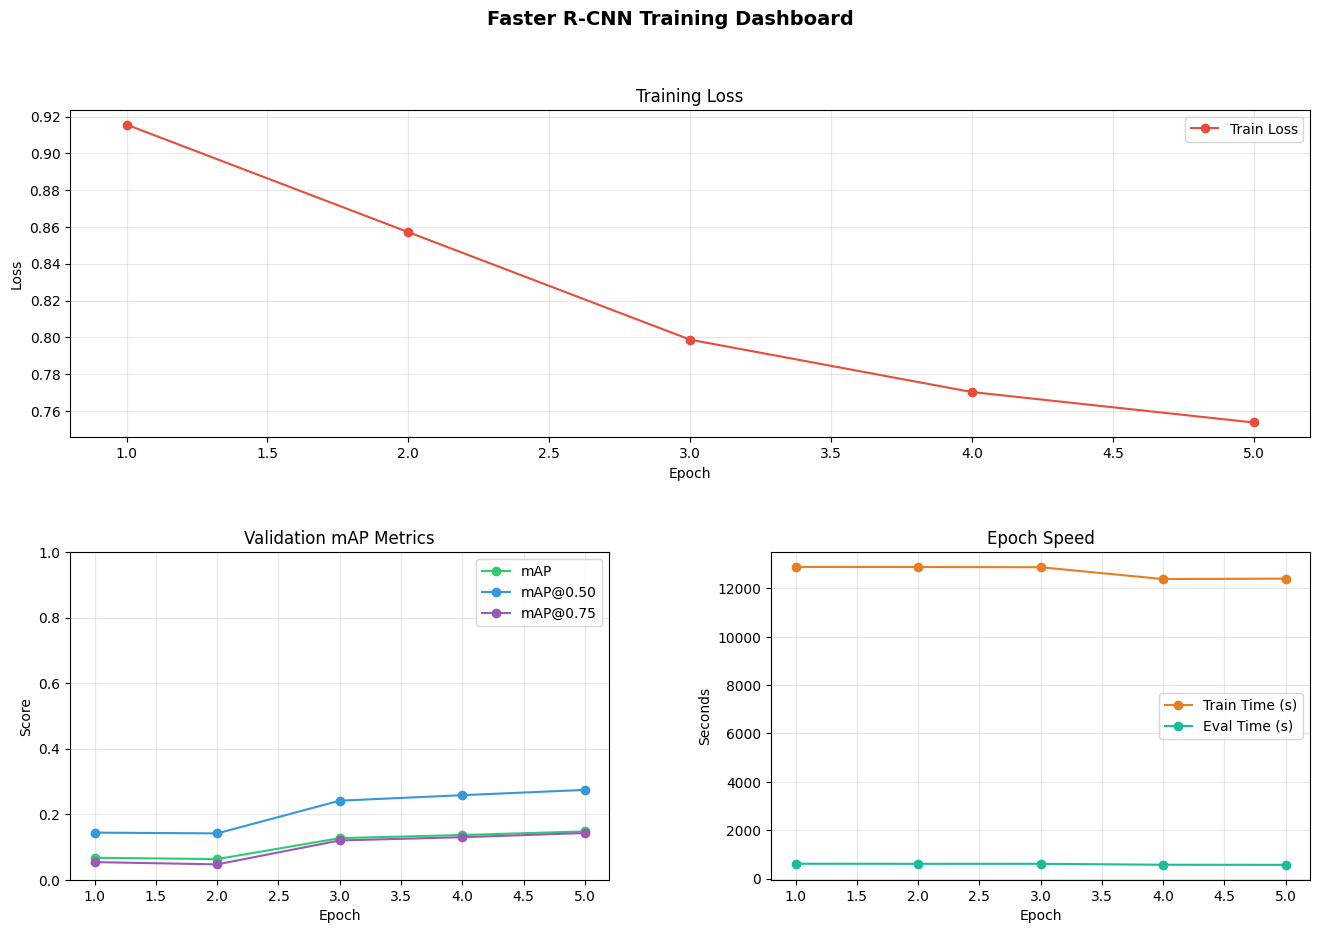

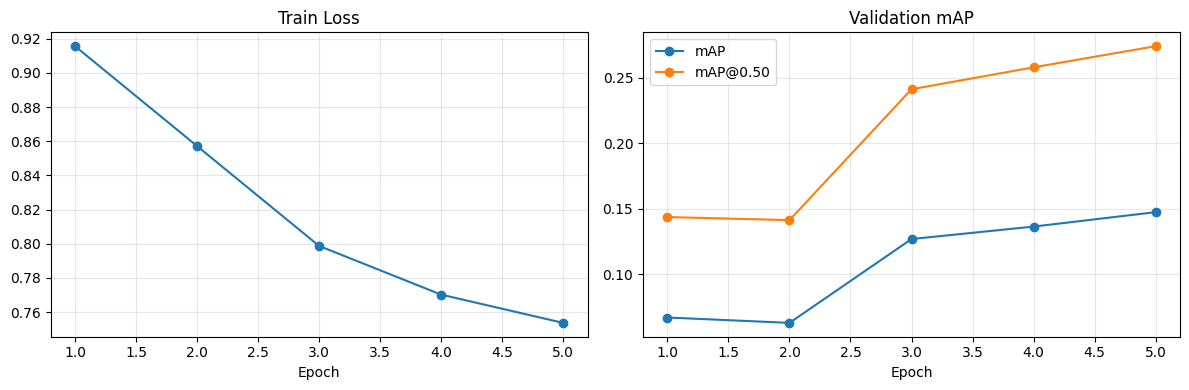

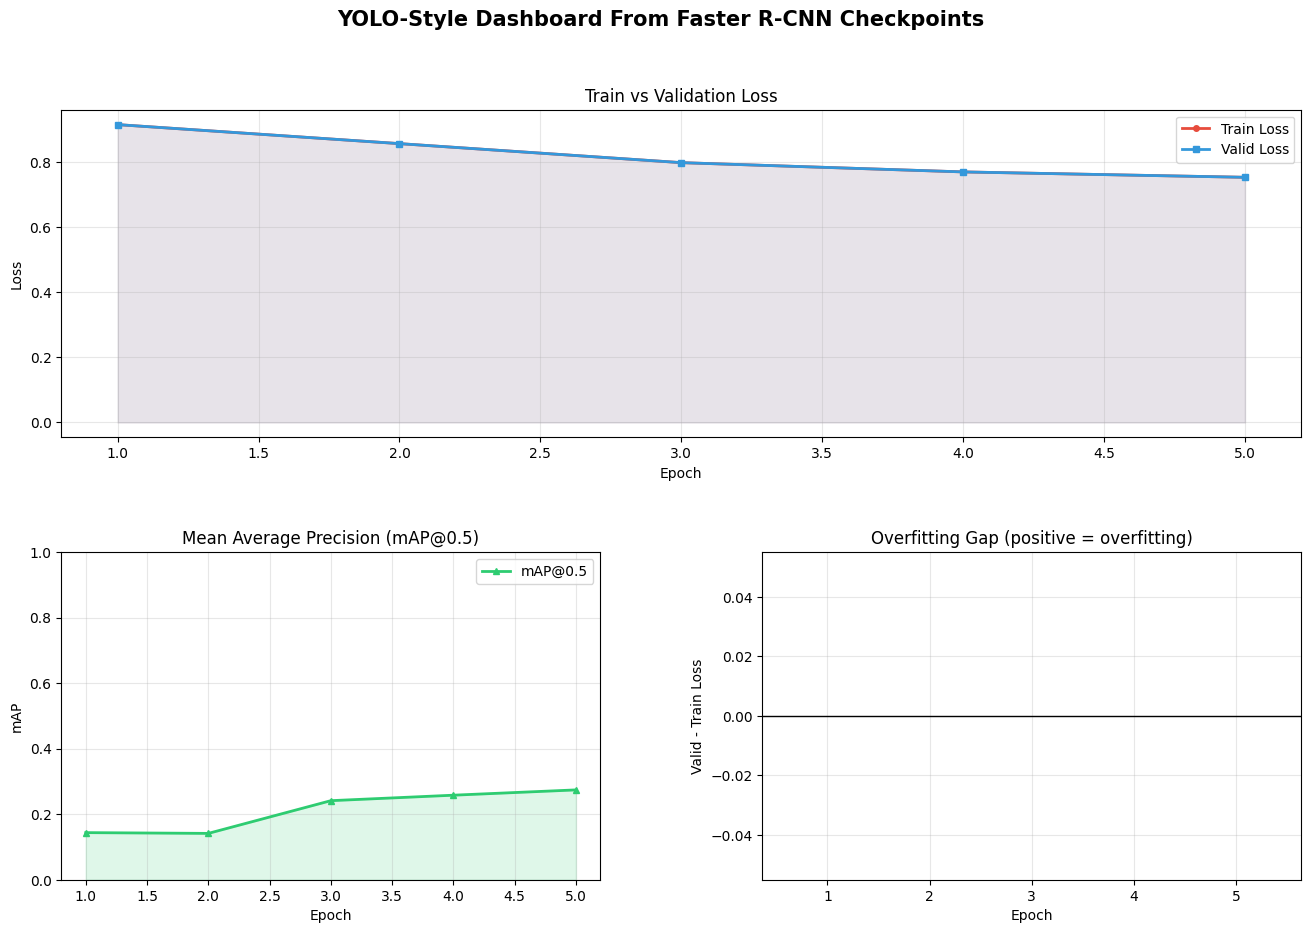

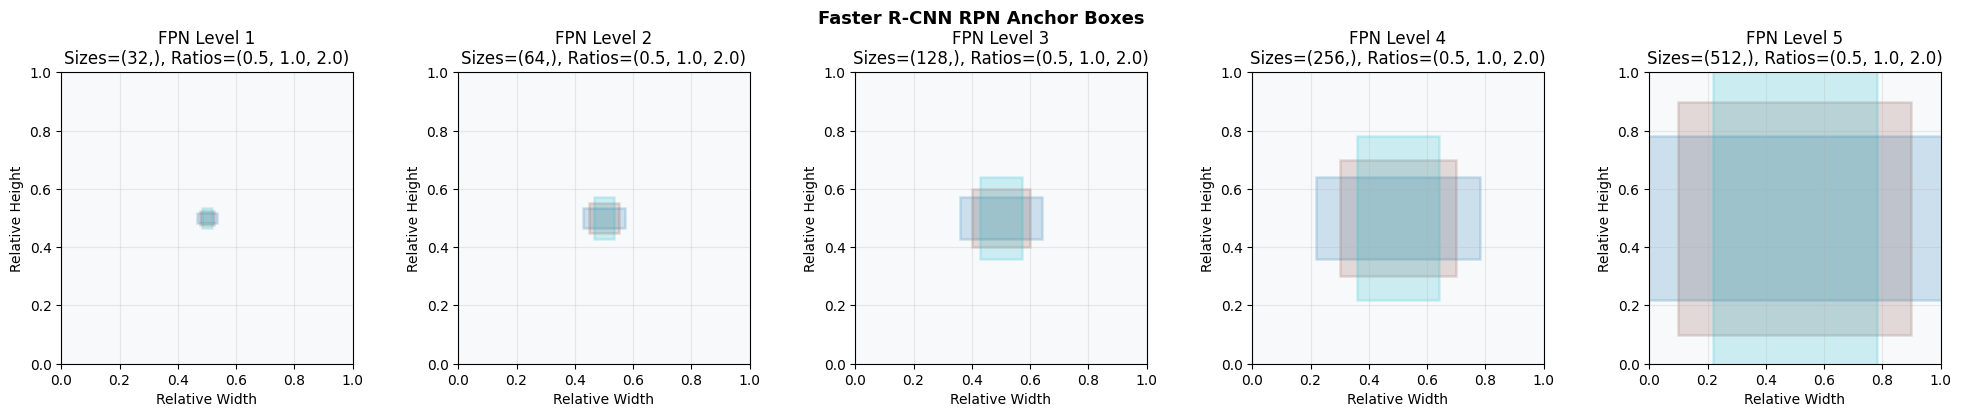

Per-class mAP is not stored in these checkpoints.
Checkpoint-based plotting complete.


In [8]:
# -----------------------------------------
# Run checkpoint-driven graphs immediately
# -----------------------------------------
plot_training_dashboard_frcnn(history)
plot_simple_training_curves_frcnn(history)

# YOLO-style dashboard using available Faster R-CNN metrics
plot_training_dashboard_yolo_style(
    train_losses=history['train_loss'],
    valid_losses=history['train_loss'],
    map_scores=history['map_50'],
    title='YOLO-Style Dashboard From Faster R-CNN Checkpoints'
)

# Anchor-box visualization (from loaded model architecture/checkpoint)
model_for_plots = build_fasterrcnn_from_checkpoint(last_ckpt)
plot_rpn_anchor_boxes(model_for_plots, image_size=640)

# Optional: if checkpoint includes class-wise metrics, visualize them
if ('map_per_class' in last_ckpt) and ('classes' in last_ckpt):
    classes = np.array(last_ckpt['classes'])
    per_ap = np.array(last_ckpt['map_per_class'])
    valid = per_ap >= 0
    names = [str(int(c)) for c in classes[valid]]
    ap_vals = [float(v) for v in per_ap[valid]]
    plot_per_class_map_from_dict(dict(zip(names, ap_vals)))
else:
    print('Per-class mAP is not stored in these checkpoints.')

print('Checkpoint-based plotting complete.')

## Optional COCO Dataset Calls

If COCO annotations are available locally, run these examples:

```python
train_ann = r"/path/to/coco2017/annotations/instances_train2017.json"
plot_coco_class_distribution_from_ann(train_ann, top_k=30, max_images=10000)
plot_bbox_size_distribution_from_ann(train_ann, max_images=10000)
```

For confidence histogram from predictions, collect a list of detection scores and call:

```python
plot_confidence_histogram_from_outputs(all_scores, threshold=0.5)
```